# Phase 1 — Exploratory Data Analysis of Order Arrivals
### Hawkes-Process-Driven Market Making · LOBSTER AAPL (2012-06-21, Level 10)

**Goal of this phase.** Before fitting any point-process model, we characterise the
*statistical nature of trade arrivals*. Specifically we ask:

1. Do executed trades arrive like a **homogeneous Poisson process** (independent, exponential
   interarrival times, constant intensity)?
2. Is there **clustering / self-excitation** (a trade makes the next trade more likely soon after)?
3. Does the evidence **motivate a Hawkes process** for the downstream market-making model?

We deliberately do **not** calibrate a Hawkes model here — that is a later phase. This notebook
only produces descriptive statistics, diagnostic plots, and formal tests.

---
## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

DATA_DIR = "../LOBSTER_SampleFile_AAPL_2012-06-21_10"
TICKER, DATE, LEVELS = "AAPL", "2012-06-21", 10
MSG_FILE = os.path.join(DATA_DIR, f"{TICKER}_{DATE}_34200000_57600000_message_{LEVELS}.csv")
OB_FILE  = os.path.join(DATA_DIR, f"{TICKER}_{DATE}_34200000_57600000_orderbook_{LEVELS}.csv")

PLOTS_DIR = "../plots"
os.makedirs(PLOTS_DIR, exist_ok=True)
print("Message file :", MSG_FILE)
print("Orderbook    :", OB_FILE)

Message file : ../LOBSTER_SampleFile_AAPL_2012-06-21_10/AAPL_2012-06-21_34200000_57600000_message_10.csv
Orderbook    : ../LOBSTER_SampleFile_AAPL_2012-06-21_10/AAPL_2012-06-21_34200000_57600000_orderbook_10.csv


## 1. Loading the LOBSTER files

LOBSTER ships **two paired CSVs per trading day**. They have the *same number of rows*: row `i`
of the orderbook file is the state of the book **immediately after** the event described by row `i`
of the message file.

### 1a. Message file — `(N x 6)`, one row per book-changing event

| # | Column | Meaning |
|---|--------|---------|
| 1 | **Time** | Seconds after midnight (≥ ms precision). Session is 34200s–57600s = 09:30–16:00. |
| 2 | **Type** | Event type causing the book update (see table below). |
| 3 | **Order ID** | Unique order reference number (from the order flow). |
| 4 | **Size** | Number of shares involved in the event. |
| 5 | **Price** | Dollar price × 10000 (e.g. `5853300` = \$585.33). |
| 6 | **Direction** | `1` = buy limit order, `-1` = sell limit order. |

**Event types (column `Type`):**

| Code | Event | Notes |
|------|-------|-------|
| **1** | Submission of a new limit order | adds liquidity |
| **2** | Partial cancellation | partial deletion of a limit order |
| **3** | Total deletion | full deletion of a limit order |
| **4** | **Execution of a visible limit order** | **a trade** — marketable order hits a resting limit order |
| **5** | **Execution of a hidden limit order** | **a trade** against hidden liquidity |
| **7** | Trading halt indicator | price/direction encode halt / quoting / resume |

> **Direction convention for executions.** Column `Direction` is the side of the *resting limit order*
> that got hit. Execution of a **sell** limit (`-1`) ⇒ a **buyer-initiated** trade (aggressor *bought*);
> execution of a **buy** limit (`+1`) ⇒ a **seller-initiated** trade. We record both the resting side
> and the inferred aggressor side.

In [2]:
# --- Message file ---
msg_cols = ["time", "event_type", "order_id", "size", "price", "direction"]
msg = pd.read_csv(MSG_FILE, header=None, names=msg_cols)

print("Message file shape:", msg.shape)
print("\nEvent-type counts:")
labels = {1:"1 new limit order", 2:"2 partial cancel", 3:"3 deletion",
          4:"4 visible execution (TRADE)", 5:"5 hidden execution (TRADE)", 7:"7 trading halt"}
print(msg["event_type"].map(labels).value_counts().reindex(
      [labels[k] for k in sorted(labels) if k in msg["event_type"].unique()]))
msg.head()

Message file shape: (400391, 6)

Event-type counts:


event_type
1 new limit order              191015
2 partial cancel                 3260
3 deletion                     171126
4 visible execution (TRADE)     23658
5 hidden execution (TRADE)      11332
Name: count, dtype: int64


,time,event_type,order_id,size,price,direction
0,34200.004241,1,16113575,18,5853300,1
1,34200.004261,1,16113584,18,5853200,1
2,34200.004447,1,16113594,18,5853100,1
3,34200.025552,1,16120456,18,5859100,-1
4,34200.025580,1,16120480,18,5859200,-1


### 1b. Orderbook file — `(N x 4·Levels)`

For a Level-10 book each row has **40 columns**, ordered as
`AskPrice1, AskSize1, BidPrice1, BidSize1, AskPrice2, …` out to level 10.

- Prices are again in **dollars × 10000**.
- *Level* means an **occupied** price level (not a fixed tick offset).
- Unoccupied levels are padded with dummy values: ask price `9999999999`, bid price `-9999999999`,
  sizes `0`.

We load it mainly to (a) confirm row-alignment with the message file and (b) reconstruct the
mid-price for context. The arrival analysis itself only needs the message file.

In [3]:
# --- Orderbook file ---
ob_cols = []
for i in range(1, LEVELS + 1):
    ob_cols += [f"ask_price_{i}", f"ask_size_{i}", f"bid_price_{i}", f"bid_size_{i}"]
ob = pd.read_csv(OB_FILE, header=None, names=ob_cols)
print("Orderbook file shape:", ob.shape)
assert len(ob) == len(msg), "Message and orderbook files must have equal row counts"

# Convert price columns to dollars; mid-price from best quotes (level 1)
for col in [c for c in ob_cols if "price" in c]:
    ob[col] = ob[col] / 10000.0
mid = (ob["ask_price_1"] + ob["bid_price_1"]) / 2.0
print(f"Rows aligned. Mid-price range: ${mid.min():.2f} - ${mid.max():.2f}")
ob[["ask_price_1","ask_size_1","bid_price_1","bid_size_1"]].head()

Orderbook file shape: (400391, 40)
Rows aligned. Mid-price range: $577.48 - $588.18


,ask_price_1,ask_size_1,bid_price_1,bid_size_1
0,585.94,200,585.33,18
1,585.94,200,585.33,18
2,585.94,200,585.33,18
3,585.91,18,585.33,18
4,585.91,18,585.33,18


## 2. A clean, analysis-ready dataframe

We collapse the raw message file into a tidy frame with exactly the requested fields:
`timestamp, event_type, side, price, size`. Price is converted to dollars and `side` is decoded
from the direction flag.

In [4]:
clean = pd.DataFrame({
    "timestamp":  msg["time"],                       # seconds after midnight
    "event_type": msg["event_type"],
    "side":       msg["direction"].map({1: "buy_limit", -1: "sell_limit"}),
    "price":      msg["price"] / 10000.0,            # dollars
    "size":       msg["size"],
})
# Human-readable event label for convenience
clean["event_label"] = clean["event_type"].map(labels)
print(clean.shape)
clean.head(8)

(400391, 6)


,timestamp,event_type,side,price,size,event_label
0,34200.004241,1,buy_limit,585.33,18,1 new limit order
1,34200.004261,1,buy_limit,585.32,18,1 new limit order
2,34200.004447,1,buy_limit,585.31,18,1 new limit order
3,34200.025552,1,sell_limit,585.91,18,1 new limit order
4,34200.025580,1,sell_limit,585.92,18,1 new limit order
5,34200.025613,1,sell_limit,585.93,18,1 new limit order
6,34200.050241,1,buy_limit,585.00,100,1 new limit order
7,34200.201518,1,sell_limit,585.93,100,1 new limit order


## 3. Executed trades only

Market-making and self-excitation are driven by **executions**, so we keep event types **4
(visible)** and **5 (hidden)** and discard submissions, cancellations and deletions. We also
decode the **aggressor side** from the resting-order direction.

In [5]:
trades = clean[clean["event_type"].isin([4, 5])].copy().reset_index(drop=True)

# Aggressor side: hit a sell limit (-1) => buyer-initiated; hit a buy limit (+1) => seller-initiated
dir_of_trades = msg.loc[msg["event_type"].isin([4, 5]), "direction"].values
trades["aggressor"] = pd.Series(dir_of_trades).map({-1: "buy", 1: "sell"}).values

n_total = len(clean)
print(f"All events            : {n_total:,}")
print(f"Executed trades (4,5) : {len(trades):,}  ({100*len(trades)/n_total:.1f}% of events)")
print(f"  visible (type 4)    : {(trades.event_type==4).sum():,}")
print(f"  hidden  (type 5)    : {(trades.event_type==5).sum():,}")
print(f"  buyer-initiated     : {(trades.aggressor=='buy').sum():,}")
print(f"  seller-initiated    : {(trades.aggressor=='sell').sum():,}")
trades.head()

All events            : 400,391
Executed trades (4,5) : 34,990  (8.7% of events)
  visible (type 4)    : 23,658
  hidden  (type 5)    : 11,332
  buyer-initiated     : 16,729
  seller-initiated    : 18,261


,timestamp,event_type,side,price,size,event_label,aggressor
0,34200.275016,4,sell_limit,585.74,40,4 visible execution (TRADE),buy
1,34200.275016,4,sell_limit,585.75,25,4 visible execution (TRADE),buy
2,34200.275057,4,buy_limit,585.73,1,4 visible execution (TRADE),sell
3,34200.275063,4,buy_limit,585.73,10,4 visible execution (TRADE),sell
4,34200.275072,4,sell_limit,585.75,25,4 visible execution (TRADE),buy


## 4. Interarrival times between trades

The interarrival time is $\tau_i = t_i - t_{i-1}$ for consecutive trade events.

**One important data-cleaning subtlety.** A single marketable order that walks the book is recorded
by LOBSTER as **several execution messages with an identical timestamp** (one per resting order /
price level it consumes). These produce $\tau_i = 0$. For an *arrival-timing* analysis we treat such
simultaneous executions as a single trade event, i.e. we keep only strictly positive interarrivals.
(The dropped count is reported below.)

For a homogeneous Poisson process the interarrivals are i.i.d. $\text{Exponential}(\lambda)$, whose
hallmark is a **coefficient of variation** $CV = \sigma/\mu = 1$. $CV > 1$ (overdispersion) is the
first fingerprint of clustering.

In [6]:
t = trades["timestamp"].values
dt_all = np.diff(t)
dt = dt_all[dt_all > 0]            # collapse simultaneous executions of one marketable order
n_zero = (dt_all <= 0).sum()

mu, sigma = dt.mean(), dt.std()
cv = sigma / mu
lam_hat = 1.0 / mu                 # MLE of Poisson rate (trades per second)

print(f"Trade events                 : {len(t):,}")
print(f"Zero/simultaneous gaps dropped: {n_zero:,}")
print(f"Positive interarrivals       : {len(dt):,}")
print(f"Mean interarrival   mu       : {mu:.4f} s")
print(f"Std  interarrival   sigma    : {sigma:.4f} s")
print(f"Coeff. of variation CV       : {cv:.3f}   (Poisson => 1.0)")
print(f"Implied trade rate  lambda   : {lam_hat:.3f} trades/s  ({lam_hat*60:.1f}/min)")

Trade events                 : 34,990
Zero/simultaneous gaps dropped: 10,129
Positive interarrivals       : 24,860
Mean interarrival   mu       : 0.9413 s
Std  interarrival   sigma    : 2.4833 s
Coeff. of variation CV       : 2.638   (Poisson => 1.0)
Implied trade rate  lambda   : 1.062 trades/s  (63.7/min)


## 5. Diagnostic figures

All figures are saved to `../plots/`.

### 5a. Histogram of interarrival times vs the exponential fit

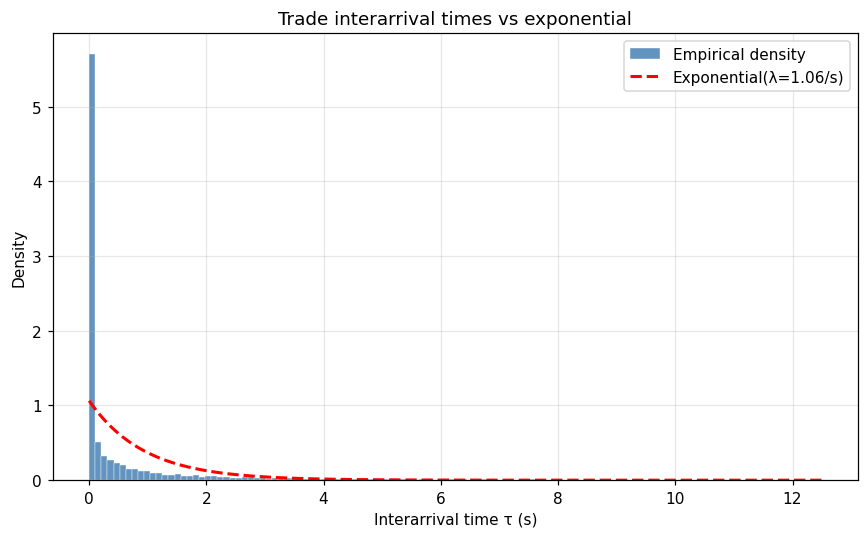

In [7]:
x_hi = np.percentile(dt, 99)            # clip extreme tail for readability
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(dt, bins=120, range=(0, x_hi), density=True,
        color="steelblue", alpha=0.85, edgecolor="white", linewidth=0.3,
        label="Empirical density")
xs = np.linspace(0, x_hi, 400)
ax.plot(xs, lam_hat*np.exp(-lam_hat*xs), "r--", lw=2,
        label=f"Exponential(λ={lam_hat:.2f}/s)")
ax.set(xlabel="Interarrival time τ (s)", ylabel="Density",
       title="Trade interarrival times vs exponential")
ax.legend(); fig.tight_layout()
fig.savefig(f"{PLOTS_DIR}/hist_interarrival.png", dpi=130, bbox_inches="tight")
plt.show()

A pure Poisson process would lie on the red dashed curve. An **excess mass of very short gaps**
(left spike above the curve) together with a **heavier right tail** is the visual signature of
clustering: bursts of near-simultaneous trades separated by longer quiet periods.

### 5b. Empirical CDF vs exponential CDF

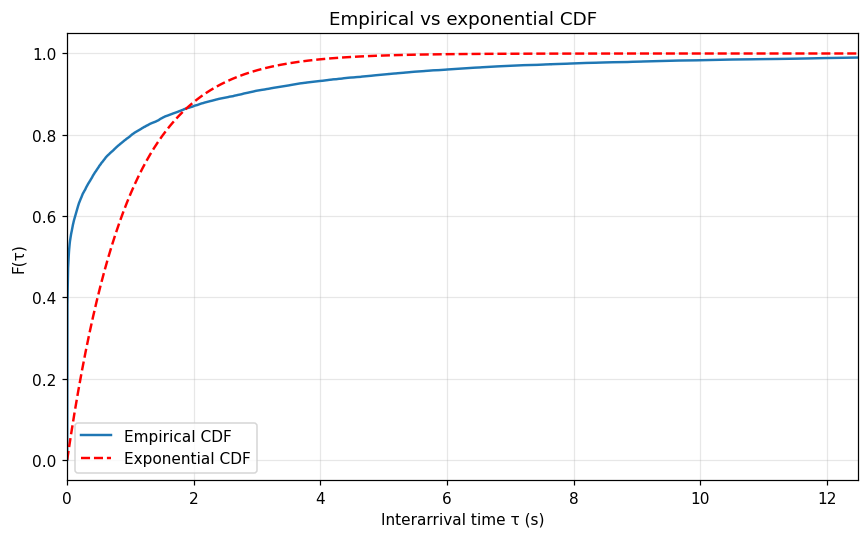

In [8]:
xs_sorted = np.sort(dt)
ecdf = np.arange(1, len(xs_sorted)+1) / len(xs_sorted)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(xs_sorted, ecdf, lw=1.6, label="Empirical CDF")
ax.plot(xs_sorted, 1-np.exp(-lam_hat*xs_sorted), "r--", lw=1.6,
        label="Exponential CDF")
ax.set_xlim(0, np.percentile(dt, 99))
ax.set(xlabel="Interarrival time τ (s)", ylabel="F(τ)",
       title="Empirical vs exponential CDF")
ax.legend(); fig.tight_layout()
fig.savefig(f"{PLOTS_DIR}/ecdf_interarrival.png", dpi=130, bbox_inches="tight")
plt.show()

The empirical CDF rises **above** the exponential at small τ (more short gaps than Poisson
predicts) — exactly what the KS test in §6 quantifies.

### 5c. Autocorrelation of interarrival times

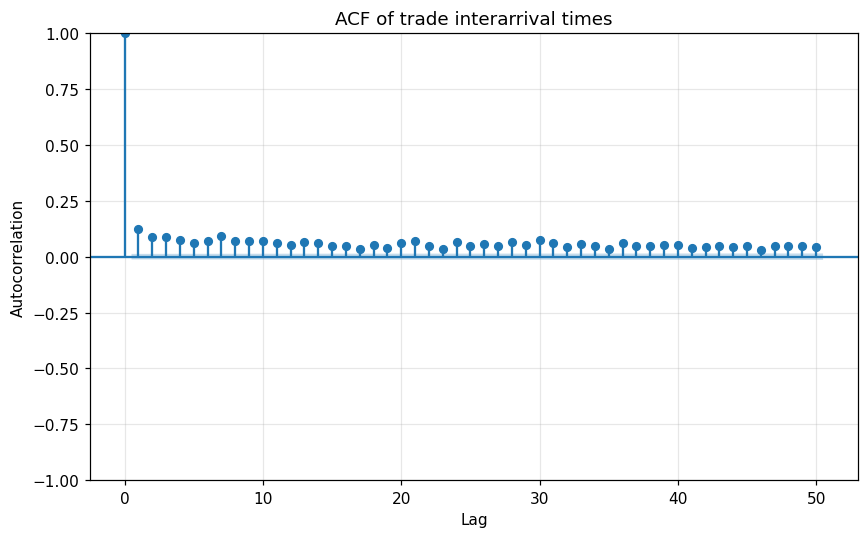

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_acf(dt, lags=50, ax=ax, alpha=0.05)
ax.set(title="ACF of trade interarrival times", xlabel="Lag", ylabel="Autocorrelation")
fig.tight_layout()
fig.savefig(f"{PLOTS_DIR}/acf_interarrival.png", dpi=130, bbox_inches="tight")
plt.show()

Under Poisson, interarrivals are **independent**, so the ACF should be ~0 at every non-zero lag
(inside the blue confidence band). **Persistent positive autocorrelation** means short gaps follow
short gaps — memory in the arrival stream that Poisson cannot reproduce but Hawkes can.

### 5d. Rolling trade arrival intensity

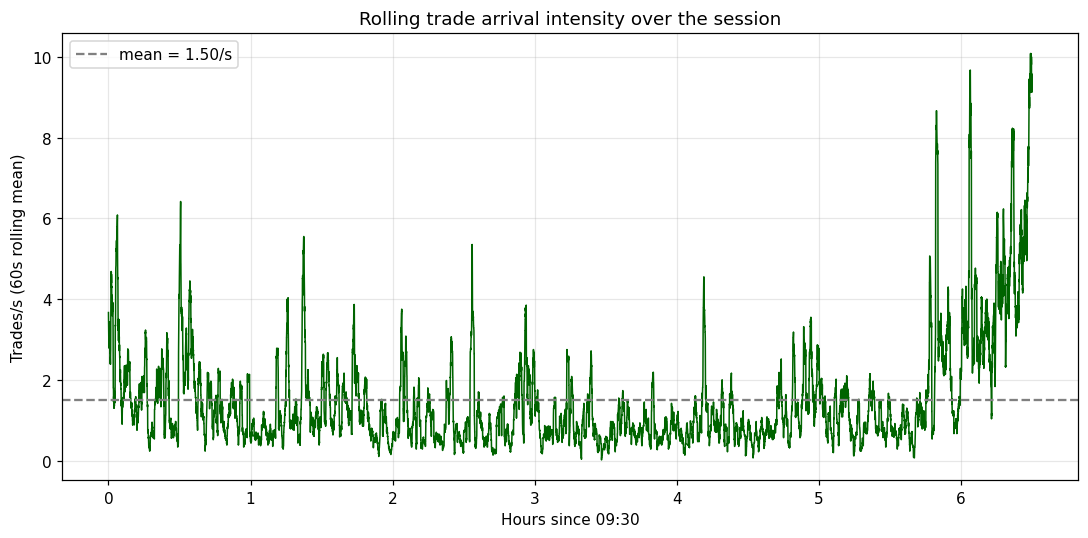

In [10]:
sec0, sec1 = int(np.floor(t.min())), int(np.ceil(t.max()))
edges = np.arange(sec0, sec1+1, 1.0)              # 1-second bins
counts, _ = np.histogram(t, bins=edges)
centers_hr = ((edges[:-1] + edges[1:]) / 2 - sec0) / 3600.0
roll = pd.Series(counts).rolling(60, min_periods=1, center=True).mean()  # 60s smoothing

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(centers_hr, roll, color="darkgreen", lw=1)
ax.axhline(counts.mean(), color="gray", ls="--", label=f"mean = {counts.mean():.2f}/s")
ax.set(xlabel="Hours since 09:30", ylabel="Trades/s (60s rolling mean)",
       title="Rolling trade arrival intensity over the session")
ax.legend(); fig.tight_layout()
fig.savefig(f"{PLOTS_DIR}/rolling_intensity.png", dpi=130, bbox_inches="tight")
plt.show()

A homogeneous Poisson process has a **constant** intensity λ. The realised intensity instead
shows the classic intraday U-shape (busy open, quiet midday) **plus sharp localised spikes** —
non-stationarity *and* bursts. Both violate homogeneous Poisson and point toward a *self-exciting*
intensity.

## 6. Formal tests

### 6a. Ljung–Box — is there serial dependence in interarrivals?
$H_0$: interarrivals are independent (white noise), as Poisson requires. Small p-values reject
independence.

### 6b. Kolmogorov–Smirnov — are interarrivals exponential?
$H_0$: τ ~ Exponential(λ̂). We use the fitted mean as the scale. A small p-value rejects the
exponential (hence Poisson) law.

In [11]:
lb = acorr_ljungbox(dt, lags=[10, 20, 50], return_df=True)
print("Ljung-Box test (H0: independent interarrivals)")
print(lb.to_string())

ks_stat, ks_p = stats.kstest(dt, "expon", args=(0, mu))
print("\nKolmogorov-Smirnov test (H0: tau ~ Exponential)")
print(f"  KS statistic = {ks_stat:.4f}")
print(f"  p-value      = {ks_p:.3e}")
print(f"  CV           = {cv:.3f}  (Exponential => 1.0)")

Ljung-Box test (H0: independent interarrivals)
        lb_stat  lb_pvalue
10  1702.362674        0.0
20  2408.646490        0.0
50  4344.614258        0.0

Kolmogorov-Smirnov test (H0: tau ~ Exponential)
  KS statistic = 0.4927
  p-value      = 0.000e+00
  CV           = 2.638  (Exponential => 1.0)


## 7. Conclusions — does this motivate a Hawkes process?

**Summary of evidence (this dataset, AAPL 2012-06-21):**

| Diagnostic | Poisson prediction | Observed | Verdict |
|---|---|---|---|
| Coefficient of variation | 1.0 | ≈ 2.6 | **overdispersed → clustering** |
| Histogram / ECDF shape | matches Exp(λ) | excess short gaps, heavy tail | **not exponential** |
| KS test vs exponential | p large | p ≈ 0 | **reject exponential** |
| ACF of interarrivals | ≈ 0 at all lags | persistent positive | **reject independence** |
| Ljung–Box | p large | p ≈ 0 | **reject independence** |
| Rolling intensity | flat at λ | U-shape + spikes | **non-stationary, bursty** |

**Are arrivals Poisson?** No. A homogeneous Poisson process is rejected on every axis: the
interarrival distribution is not exponential (KS), the interarrivals are not independent
(Ljung–Box, ACF), and the intensity is not constant (rolling plot). $CV \approx 2.6 \gg 1$ confirms
strong overdispersion.

**Evidence of clustering.** Trades arrive in **bursts**: an excess of very short interarrivals, a
heavy right tail, positive autocorrelation that decays slowly, and visible intensity spikes. Trades
beget trades — the signature of *self-excitation*.

**Why a Hawkes process.** A Hawkes process has a conditional intensity

$$\lambda(t) = \mu + \sum_{t_i < t} \alpha\, e^{-\beta (t - t_i)},$$

a baseline rate $\mu$ plus a **self-exciting** kernel: each past trade transiently raises the
probability of the next one. This directly reproduces exactly what we observed — overdispersion,
short-gap excess, positive interarrival autocorrelation, and intensity clustering — none of which a
Poisson model can capture. It is therefore the natural arrival model for the market-making engine.

> **Next phase (not done here):** calibrate the Hawkes intensity (estimate μ, α, β; possibly a
> marked / multivariate buy-vs-sell specification) and validate via the time-rescaling theorem.
> A companion `eda_report.md` accompanies this notebook.